In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

import warnings
warnings.filterwarnings("ignore", message=".*inplace keyword.*")

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
ticker = 'NVDA'
df = yf.download(ticker, '2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [4]:
df

Price,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA
Date,,,,,
2020-01-02,5.957136,5.957136,5.877927,5.928333,237536000
2020-01-03,5.861787,5.905490,5.812871,5.837701,205384000
2020-01-06,5.886371,5.891586,5.742602,5.768674,262636000
2020-01-07,5.957633,6.003322,5.869733,5.914676,314856000
2020-01-08,5.968809,6.010028,5.913436,5.953414,277108000
...,...,...,...,...,...
2026-10-27,217.940002,219.190002,215.529999,218.309998,84799700
2026-10-28,215.380005,219.990005,214.470001,219.919998,93030200


<Axes: xlabel='Date'>

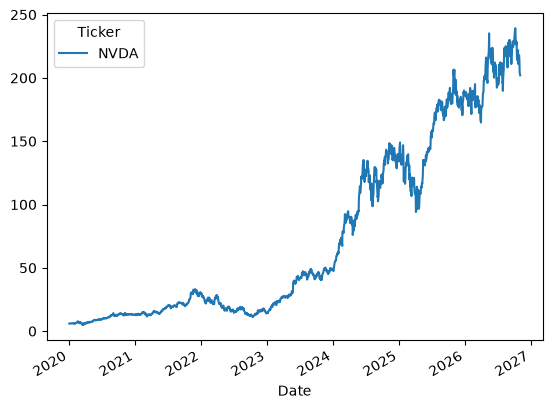

In [5]:
df.Close.plot()

In [ ]:
split_row = int(0.8 * len(df))

scaler = StandardScaler()
scaler.fit(df['Close'].iloc[:split_row])
df['Close'] = scaler.transform(df['Close'])

In [7]:
df.Close

Ticker,NVDA
Date,
2020-01-02,-0.968501
2020-01-03,-0.969834
2020-01-06,-0.969490
2020-01-07,-0.968494
2020-01-08,-0.968338
...,...
2026-10-27,1.993520
2026-10-28,1.957749
2026-10-29,1.933716


In [8]:
seq_length = 30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

In [ ]:
train_size = split_row - seq_length + 1

X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

In [10]:
X_train

tensor([[[-0.9685],
         [-0.9698],
         [-0.9695],
         ...,
         [-0.9605],
         [-0.9588],
         [-0.9572]],

        [[-0.9698],
         [-0.9695],
         [-0.9685],
         ...,
         [-0.9588],
         [-0.9572],
         [-0.9578]],

        [[-0.9695],
         [-0.9685],
         [-0.9683],
         ...,
         [-0.9572],
         [-0.9578],
         [-0.9512]],

        ...,

        [[ 0.7592],
         [ 0.8346],
         [ 0.8275],
         ...,
         [ 0.9533],
         [ 0.9578],
         [ 1.0098]],

        [[ 0.8346],
         [ 0.8275],
         [ 0.8354],
         ...,
         [ 0.9578],
         [ 1.0098],
         [ 1.0991]],

        [[ 0.8275],
         [ 0.8354],
         [ 0.8378],
         ...,
         [ 1.0098],
         [ 1.0991],
         [ 1.1090]]])

In [11]:
y_train

tensor([[-0.9578],
        [-0.9512],
        [-0.9488],
        ...,
        [ 1.0991],
        [ 1.1090],
        [ 1.1471]])

In [12]:
class PredictionModel(nn.Module):

    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)

        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])

        return out

In [13]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [14]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr = 0.01)

In [15]:
num_epochs = 200
for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, y_train)

    if i % 25 == 0:
        print(i, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 0.4413379728794098
25 0.01868285983800888
50 0.0035390942357480526
75 0.0020631584338843822
100 0.0017843175446614623
125 0.0016674548387527466
150 0.0015803592978045344
175 0.0015028073685243726


In [16]:
model.eval()

y_train_pred = model(X_train)
y_test_pred = model(X_test)

y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())

In [17]:
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])

In [18]:
train_rmse

2.7054309844970703

In [19]:
test_rmse

11.686271667480469

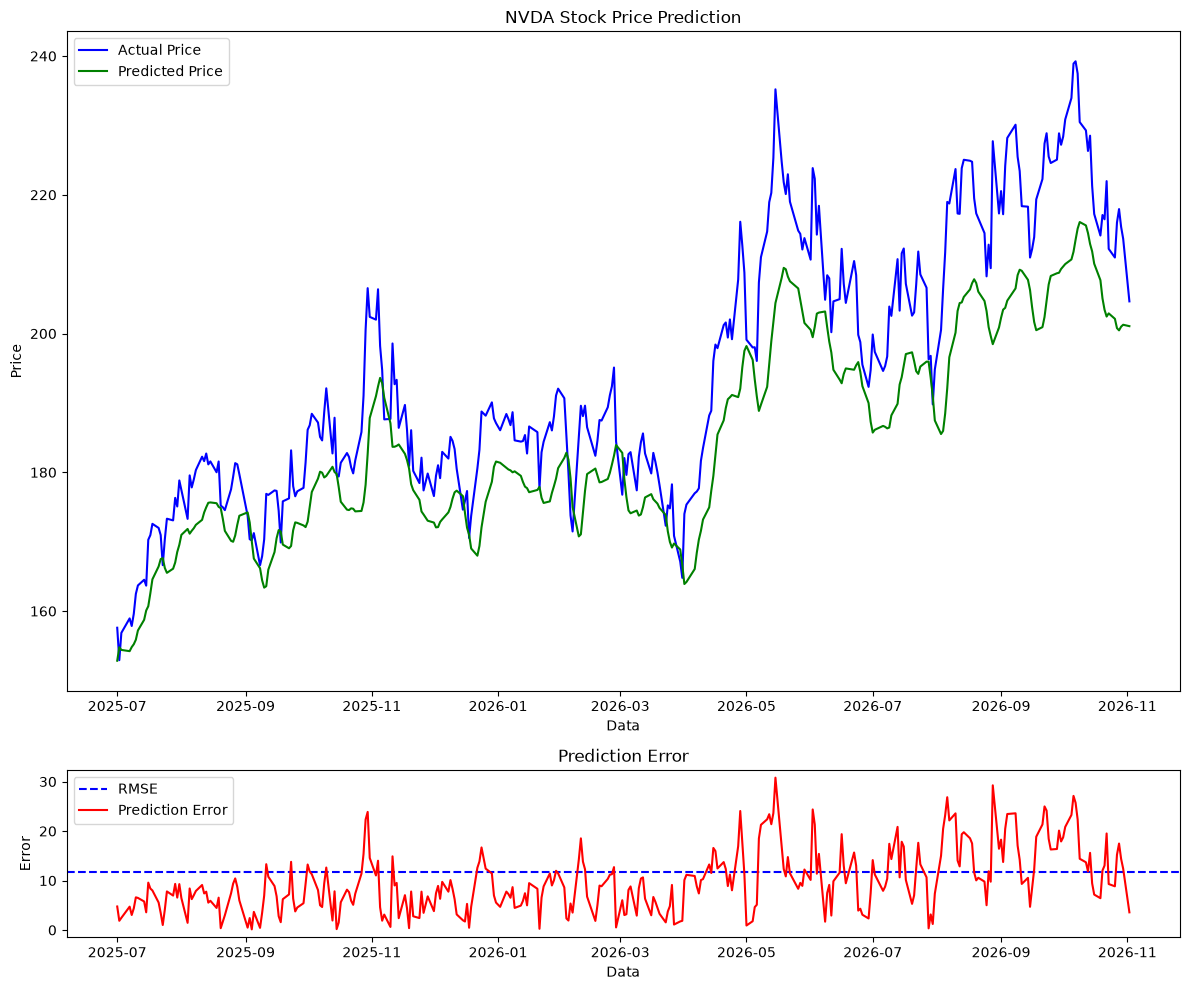

In [20]:
fig = plt.figure(figsize=(12, 10))

gs = fig.add_gridspec(4, 1)

ax1 = fig.add_subplot(gs[:3, 0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color = 'blue', label = 'Actual Price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color = 'green', label = 'Predicted Price')
ax1.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel('Data')
plt.ylabel('Price')

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = 'blue', linestyle = '--', label = 'RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), 'r', label = 'Prediction Error')
ax2.legend()
plt.title('Prediction Error')
plt.xlabel('Data')
plt.ylabel('Error')

plt.tight_layout()
plt.show()